# Supplemental Figures S1–S4 — Allele-specific expression and promoter structural variation

Supporting panels for the same analysis as `Fig2_ASE_SV_promoter_analysis_main.ipynb`:
- **S1.** Novel vs. annotated genes and isoforms
- **S2.** Allelic ratio differences, short- vs. long-read RNA-seq (FDR comparison)
- **S3.** Promoter SVs vs. allelic balance status: number of SVs / promoter identity (bar plots) and SV density relative to the TSS
- **S4.** Transposable-element class of promoter SVs

Additional plots (not in the figure): small variants (<20bp) vs. allelic log2FC and number of small variants by balance status.

Inputs: `clean_data/Fig2_ASE_SV_promoter_analysis/`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns


## Setup

In [2]:
DATA_DIR = "clean_data/Fig2_ASE_SV_promoter_analysis"
OUT_DIR  = "./figures/FigS"
import os
os.makedirs(OUT_DIR, exist_ok=True)


## Panel S1 — Novel vs. annotated genes and isoforms

Purely from the transcript-to-gene annotation (`combined.tx2gene.tsv`); a gene/isoform is
"novel" if Bambu or StringTie/XLOC assembled it de novo from the long-read data rather than
lifting it over from the reference annotation.

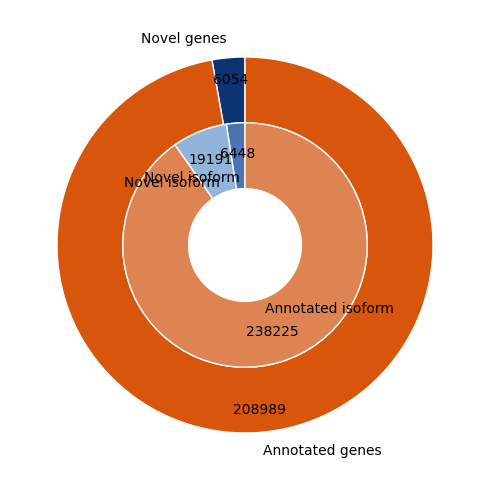

In [3]:
counts = pd.read_csv(f"{DATA_DIR}/novel_gene_isoform_counts.csv").set_index("category")["count"]

outer_sizes  = [counts["novel_genes"], counts["annotated_genes"]]
outer_colors = ["#0C3474", "#D7560C"]

inner_sizes  = [counts["novel_gene_novel_isoform"], counts["annotated_gene_novel_isoform"], counts["annotated_gene_annotated_isoform"]]
inner_colors = ["#4C72B0", "#92b4d9", "#DD8452"]
inner_labels = ["Novel isoform", "Novel isoform", "Annotated isoform"]

fig, ax = plt.subplots(figsize=(5, 5))

total = sum(outer_sizes)
ax.pie(outer_sizes, radius=1.0, labels=["Novel genes", "Annotated genes"], colors=outer_colors,
       autopct=lambda p: f"{int(round(p * total / 100))}", pctdistance=0.88,
       wedgeprops=dict(width=0.35, edgecolor="white"), startangle=90)
total = sum(inner_sizes)
ax.pie(inner_sizes, radius=0.65, labels=inner_labels, labeldistance=0.55, colors=inner_colors,
       autopct=lambda p: f"{int(round(p * total / 100))}", pctdistance=0.75,
       wedgeprops=dict(width=0.35, edgecolor="white"), startangle=90)

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/FigS1_novel_genes_isoforms_pie_chart.svg", format="svg")
plt.show()


## Panel S2 — Allelic ratio differences, short- vs. long-read RNA-seq

Long-read RNA-seq calls more imbalanced syntelogs than short-read RNA-seq (EM counts). Both use
the same test (`poly.test_allelic_ratios_within_conditions`, control samples) and the same call
(FDR < 0.05 and ratio difference > 0.1). Restricted to single-isoform syntelogs (`n_transcripts == 1`)
tested in both technologies; per syntelog, the largest allele ratio difference and the smallest FDR.

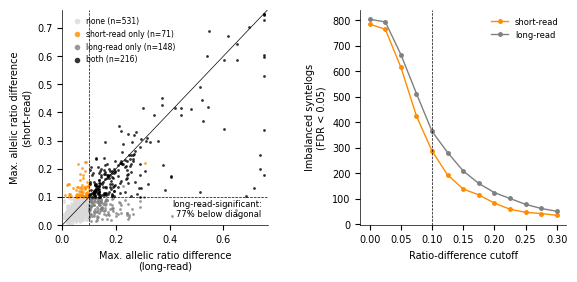

syntelogs tested in both (single isoform): 966
category
none               531
short-read only     71
long-read only     148
both               216
long-read-significant: 77% smaller ratio difference in short reads, median short/long = 0.74
 cutoff  short  long
  0.000    784   803
  0.025    764   793
  0.050    615   665
  0.075    424   512
  0.100    287   364
  0.125    193   281
  0.150    138   209
  0.175    115   160
  0.200     83   124
  0.225     59   101
  0.250     47    78
  0.275     42    62
  0.300     35    51


In [3]:
FDR_CUTOFF, RD_CUTOFF = 0.05, 0.1

short = pd.read_csv(f"{DATA_DIR}/short_cis_results_1mm_em_counts_control.tsv")
long  = pd.read_csv(f"{DATA_DIR}/long_cis_results_control.tsv")
n_tx  = (pd.read_csv(f"{DATA_DIR}/short_read_multimapping_counts.csv")
         .drop_duplicates("Synt_id").set_index("Synt_id")["n_transcripts"])

# one row per syntelog: largest allele ratio difference and smallest FDR
def per_syntelog(df):
    return df.groupby("Synt_id").agg(rd=("ratio_difference", "max"), fdr=("FDR", "min"))

ase = (per_syntelog(short).join(per_syntelog(long), lsuffix="_short", rsuffix="_long", how="inner")
       .join(n_tx, how="left"))
ase = ase[ase["n_transcripts"] == 1]  # single-isoform syntelogs tested in both technologies

sig_short = (ase["fdr_short"] < FDR_CUTOFF) & (ase["rd_short"] > RD_CUTOFF)
sig_long  = (ase["fdr_long"]  < FDR_CUTOFF) & (ase["rd_long"]  > RD_CUTOFF)
ase["category"] = np.select([sig_short & sig_long, sig_long, sig_short],
                            ["both", "long-read only", "short-read only"], "none")

cat_order   = ["none", "short-read only", "long-read only", "both"]
cat_palette = {"none": "#d9d9d9", "short-read only": "darkorange",
               "long-read only": "grey", "both": "black"}

with plt.rc_context({"font.size": 7, "axes.linewidth": 0.5}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.5, 2.8), gridspec_kw={"wspace": 0.45})

    # (i) ratio difference long vs short
    for cat in cat_order:
        sub = ase[ase["category"] == cat]
        ax1.scatter(sub["rd_long"], sub["rd_short"], s=4, lw=0, alpha=0.8,
                    color=cat_palette[cat], label=f"{cat} (n={len(sub)})")
    lim = max(ase["rd_long"].max(), ase["rd_short"].max()) * 1.02
    ax1.plot([0, lim], [0, lim], color="k", lw=0.5)
    ax1.axvline(RD_CUTOFF, color="k", ls="--", lw=0.5)
    ax1.axhline(RD_CUTOFF, color="k", ls="--", lw=0.5)
    ax1.set_xlim(0, lim)
    ax1.set_ylim(0, lim)
    ax1.set_xlabel("Max. allelic ratio difference\n(long-read)")
    ax1.set_ylabel("Max. allelic ratio difference\n(short-read)")
    lr_sig = ase[sig_long]
    frac_below = (lr_sig["rd_short"] < lr_sig["rd_long"]).mean()
    median_rel = (lr_sig["rd_short"] / lr_sig["rd_long"]).median()
    ax1.text(0.97, 0.03, f"long-read-significant:\n{frac_below:.0%} below diagonal",
             transform=ax1.transAxes, ha="right", va="bottom", fontsize=6)
    ax1.legend(fontsize=5.5, frameon=False, markerscale=2, loc="upper left", handletextpad=0.2)

    # (ii) number of imbalanced syntelogs vs ratio-difference cutoff (same FDR)
    cutoffs = np.arange(0, 0.301, 0.025)
    n_short = [((ase["fdr_short"] < FDR_CUTOFF) & (ase["rd_short"] > t)).sum() for t in cutoffs]
    n_long  = [((ase["fdr_long"]  < FDR_CUTOFF) & (ase["rd_long"]  > t)).sum() for t in cutoffs]
    ax2.plot(cutoffs, n_short, marker="o", ms=2.5, lw=1, color="darkorange", label="short-read")
    ax2.plot(cutoffs, n_long,  marker="o", ms=2.5, lw=1, color="grey", label="long-read")
    ax2.axvline(RD_CUTOFF, color="k", ls="--", lw=0.5)
    ax2.set_xlabel("Ratio-difference cutoff")
    ax2.set_ylabel(f"Imbalanced syntelogs\n(FDR < {FDR_CUTOFF})")
    ax2.legend(fontsize=6, frameon=False)

    sns.despine(fig=fig)
    plt.savefig(f"{OUT_DIR}/FigS2_ASE_ratio_difference_short_vs_long.svg", format="svg", dpi=300, bbox_inches="tight")
    plt.show()

print(f"syntelogs tested in both (single isoform): {len(ase)}")
print(ase["category"].value_counts().reindex(cat_order).to_string())
print(f"long-read-significant: {frac_below:.0%} smaller ratio difference in short reads, "
      f"median short/long = {median_rel:.2f}")
print(pd.DataFrame({"cutoff": cutoffs.round(3), "short": n_short, "long": n_long}).to_string(index=False))

## Panel S3 — Promoter SVs vs. allelic balance status

### S3a — Number of SVs / promoter identity

For every haplotype pair tested for allelic imbalance: (A) how many large (>50bp)
structural variants sit in the promoter, and (B) for pairs with zero large SVs, what
fraction of the promoter sequence is still identical (small variants only).

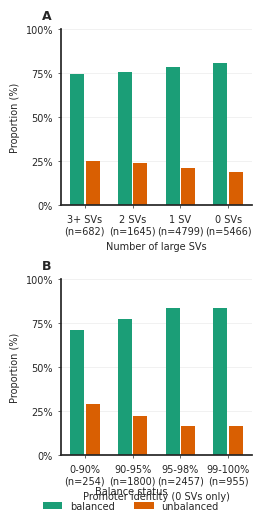

In [5]:
PROMOTER_LENGTH = 2500

df = pd.read_csv(f"{DATA_DIR}/merged_grouped_for_pie_chart.csv")

df["sv_group"] = df["num_large_sv"].apply(lambda x: str(x) if x <= 2 else "3+")
df["identity"] = 1 - df["sv_len_short"] / PROMOTER_LENGTH

bin_edges  = [0, 0.9, 0.95, 0.98, 1.001]
bin_labels = ["0-90%", "90-95%", "95-98%", "99-100%"]
mask0 = df["sv_group"] == "0"
df["identity_group"] = None
df.loc[mask0, "identity_group"] = pd.cut(
    df.loc[mask0, "identity"], bins=bin_edges, labels=bin_labels, include_lowest=True, right=True
).astype(str)
df["balance_status"] = df["balance_status"].astype(str)

balance_values = sorted(df["balance_status"].unique())
balance_palette = {bal: color for bal, color in zip(
    balance_values, ["#1b9e77", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02"])}

def to_pct(ct):
    return ct.div(ct.sum(axis=1), axis=0) * 100

ct0_raw = (df[mask0].groupby(["identity_group", "balance_status"], observed=True).size()
           .unstack(fill_value=0).reindex(index=bin_labels, columns=balance_values, fill_value=0))
ct0 = to_pct(ct0_raw)
ct0_labels = [f"{g}\n(n={ct0_raw.loc[g].sum()})" for g in ct0_raw.index]

sv_order = ["3+", "2", "1", "0"]
ctSV_raw = (df.groupby(["sv_group", "balance_status"], observed=True).size()
            .unstack(fill_value=0).reindex(index=sv_order, columns=balance_values, fill_value=0))
ctSV_raw.index = ["3+ SVs", "2 SVs", "1 SV", "0 SVs"]
ctSV = to_pct(ctSV_raw)
ctSV_labels = [f"{g}\n(n={ctSV_raw.loc[g].sum()})" for g in ctSV_raw.index]

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 7, "axes.linewidth": 0.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5,
    "xtick.bottom": True, "ytick.left": True,
})
plt.style.use("seaborn-v0_8-white")

def grouped_bar_ax(ax, ct_pct, ct_raw, xticklabels, xlabel):
    n_groups, n_bars = len(ct_pct), len(balance_values)
    width = 0.65 / n_bars
    x = np.arange(n_groups)
    for i, bal in enumerate(balance_values):
        offsets = x + (i - n_bars / 2 + 0.5) * width
        ax.bar(offsets, ct_pct[bal].values, width=width * 0.9, color=balance_palette[bal], label=bal, linewidth=0)
    ax.set_xticks(x)
    ax.set_xticklabels(xticklabels, fontsize=7)
    ax.set_xlabel(xlabel, fontsize=7, labelpad=4)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.yaxis.set_major_formatter(mticker.PercentFormatter())
    ax.set_ylabel("Proportion (%)", fontsize=7)
    ax.tick_params(axis="both", labelsize=7, length=2.5)
    ax.grid(axis="y", color="0.90", linewidth=0.4, linestyle="-")
    ax.set_axisbelow(True)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(2.5, 5), constrained_layout=True)
grouped_bar_ax(ax1, ctSV, ctSV_raw, ctSV_labels, "Number of large SVs")
grouped_bar_ax(ax2, ct0, ct0_raw, ct0_labels, "Promoter identity (0 SVs only)")
for ax, label in zip([ax1, ax2], ["A", "B"]):
    ax.text(-0.10, 1.04, label, transform=ax.transAxes, fontsize=9, fontweight="bold", va="bottom")

handles = [plt.Rectangle((0, 0), 1, 1, color=balance_palette[b], linewidth=0) for b in balance_values]
fig.legend(handles, balance_values, ncol=len(balance_values), loc="lower center",
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=7, title="Balance status", title_fontsize=7)

fig.savefig(f"{OUT_DIR}/FigS3a_SV_bar_charts.svg", bbox_inches="tight", dpi=300)
plt.show()
plt.style.use("default")
plt.rcParams.update(plt.rcParamsDefault)


### S3b — Density of promoter SVs relative to the TSS, by balance status

All structural variants in the promoter (not just the "exactly one large SV" subset used in
the main figure), binned into 50bp windows and normalized by the number of gene pairs in
each balance-status group.

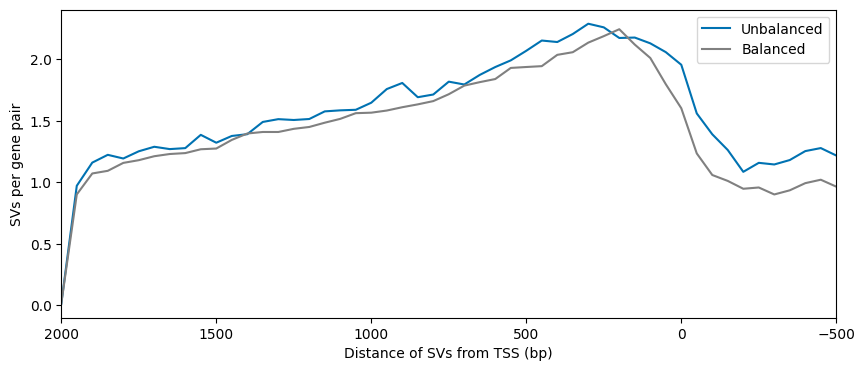

In [8]:
sv_density = pd.read_csv(f"{DATA_DIR}/sv_density_by_distance_from_tss.csv")

plt.figure(figsize=(10, 4))
sns.lineplot(data=sv_density[sv_density["balance_status"] == "unbalanced"],
             x="ref_dist_tss", y="sv_count", color="#0072B2", label="Unbalanced")
sns.lineplot(data=sv_density[sv_density["balance_status"] == "balanced"],
             x="ref_dist_tss", y="sv_count", color="grey", label="Balanced")
plt.xlabel("Distance of SVs from TSS (bp)")
plt.ylabel("SVs per gene pair")
plt.xlim(-500, 2000)
plt.gca().invert_xaxis()
plt.savefig(f"{OUT_DIR}/FigS3b_SV_density_by_distance_from_TSS.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()


## Panel S4 — Transposable-element class of promoter SVs

Restricted to haplotype pairs with exactly one large (>50bp) SV in the promoter, classified
by BLAST search against a TE library.

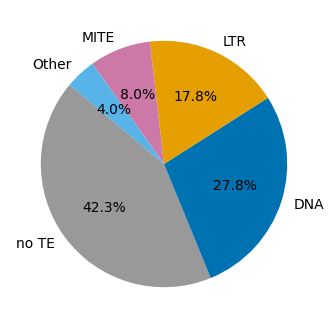

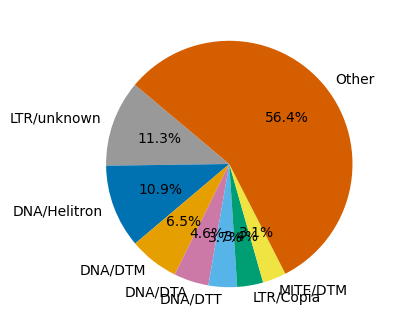

In [6]:
merged_grouped_one_sv = pd.read_csv(f"{DATA_DIR}/SV_analysis_50_one_sv.csv")

okabe_ito = ["#999999", "#0072B2", "#E69F00", "#CC79A7", "#56B4E9", "#009E73", "#F0E442", "#D55E00"]

def te_pie(column, filename):
    counts = merged_grouped_one_sv[column].value_counts()
    counts = counts[counts > counts.sum() * 0.05]
    counts["Other"] = (~merged_grouped_one_sv[column].isin(counts.index)).sum()
    colors = [okabe_ito[i % len(okabe_ito)] for i in range(len(counts))]
    plt.figure(figsize=(4, 4))
    plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140, colors=colors)
    plt.savefig(f"{OUT_DIR}/{filename}", format="svg")
    plt.show()

te_pie("TE_class_broad", "FigS4a_TE_class_broad_distribution_pie_chart.svg")
te_pie("TE_class", "FigS4b_TE_class_distribution_pie_chart.svg")


## Additional plots (not in the figure)

### Small variants (<20bp): distance to TSS vs. allelic log2FC

Restricted to small variants downstream of the TSS-relative promoter start, mirroring the
main figure's Panel B but for small rather than large structural variants.

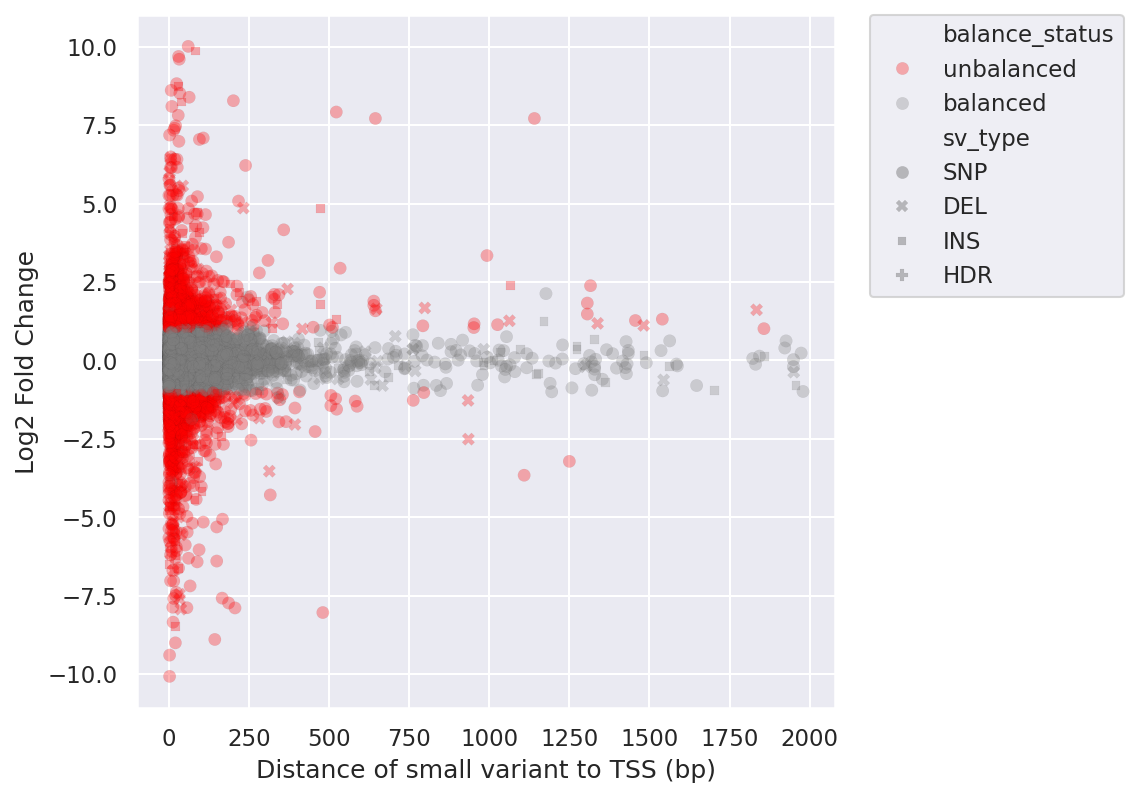

In [10]:
merged_grouped_small = pd.read_csv(f"{DATA_DIR}/merged_grouped_small.csv")

plt.subplots(figsize=(6, 6))
plt.gcf().set_dpi(150)
sns.scatterplot(
    data=merged_grouped_small, x="ref_dist_tss", y="log2FC",
    hue="balance_status", style="sv_type",
    palette={"balanced": "grey", "unbalanced": "red"},
    alpha=0.3, sizes=(40, 300), linewidth=0.05, edgecolor="k")
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.0)
plt.xlabel("Distance of small variant to TSS (bp)")
plt.ylabel("Log2 Fold Change")
plt.savefig(f"{OUT_DIR}/FigS_extra_small_variant_distance_vs_log2FC.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()


### Small variants: number of SVs by balance status

Balanced promoter pairs vs. unbalanced ones (by expression), compared for how many small
variants (<20bp) their promoters carry.

/tmp/ipykernel_2727324/3148488248.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=merged_grouped_small, x="balance_status", y="num_sv",


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

unbalanced vs. balanced: t-test independent samples, P_val:4.931e-05 t=4.060e+00


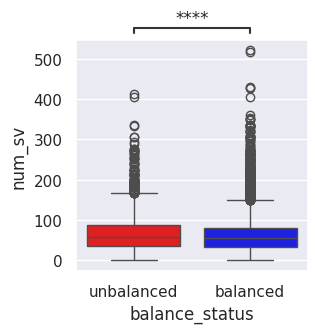

Mann-Whitney U: stat=12103481.50, p=0.0000
t-test: stat=-4.06, p=0.0000


In [11]:
from statannotations.Annotator import Annotator
from scipy import stats

fig, ax = plt.subplots(figsize=(3, 3))
sns.boxplot(data=merged_grouped_small, x="balance_status", y="num_sv",
            palette={"balanced": "blue", "unbalanced": "red"}, ax=ax)

annotator = Annotator(ax, [("balanced", "unbalanced")],
                       data=merged_grouped_small, x="balance_status", y="num_sv")
annotator.configure(test="t-test_ind", text_format="star", loc="outside")
annotator.apply_test()
annotator.annotate()
plt.savefig(f"{OUT_DIR}/FigS_extra_small_variant_num_sv_by_balance_status.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()

balanced = merged_grouped_small[merged_grouped_small["balance_status"] == "balanced"]["num_sv"]
unbalanced = merged_grouped_small[merged_grouped_small["balance_status"] == "unbalanced"]["num_sv"]
u_stat, u_p = stats.mannwhitneyu(balanced, unbalanced, alternative="two-sided")
t_stat, t_p = stats.ttest_ind(balanced, unbalanced)
print(f"Mann-Whitney U: stat={u_stat:.2f}, p={u_p:.4f}")
print(f"t-test: stat={t_stat:.2f}, p={t_p:.4f}")
